# DCR vs colour: populations and spectra (James, meeting 2026-10-2x)

James: (1) plot magnitude vs colour for the stars in the refraction-vs-colour diagram (`dcr-plots` / `dcr-polyfit`) to
confirm the bimodal colour distribution; (2) check whether any of those stars have spectra, to see whether the
SEDs behind a given colour differ (which a colour-only DCR model cannot follow).

Spectra: DESI DR1 Milky Way Survey VAC (`mwsall-pix-iron.fits`, RVSpecFit T_eff, log g, [Fe/H], [α/Fe]), matched by
Gaia `source_id` (= our `ref_id`). Epochs: `dcr_fit.load_stage_sample` (σ < 10 mas, measured g−i, offsets along the
parallactic direction before (`par_raw`) and after (`par_dcr`) the two-line DCR correction). Internal figures go to
`run/plots/`.

In [1]:
import os, sys
import numpy as np
import fitsio
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, dcr_geometry, plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
OUT = 'plots/'
MWS = '/global/cfs/cdirs/desi/public/dr1/vac/dr1/mws/iron/v1.0/mwsall-pix-iron.fits'
DEGREES = [f'{d:03d}' for d in range(64)]

In [2]:
# DESI DR1 MWS: one primary, successful RVSpecFit fit per star, good S/N, no warnings
M = fitsio.read(MWS, ext='RVTAB', columns=['REF_ID', 'REF_CAT', 'TEFF', 'LOGG', 'FEH', 'ALPHAFE', 'FEH_ERR', 'TEFF_ERR',
                                           'RVS_WARN', 'SUCCESS', 'PRIMARY', 'SN_R', 'TARGET_RA', 'TARGET_DEC'])
good = (M['PRIMARY'] & M['SUCCESS'] & (M['RVS_WARN'] == 0) & (M['SN_R'] > 10) & (M['FEH_ERR'] < 0.2)
        & (np.char.strip(M['REF_CAT'].astype(str)) == 'G2') & (M['TARGET_RA'] < 64))
M = M[good]
_, first = np.unique(M['REF_ID'], return_index=True)
M = M[first]
print(f'{len(M):,} DESI MWS stars with good parameters at RA < 64')

279,474 DESI MWS stars with good parameters at RA < 64


In [3]:
# match per slice (parallel; cached): our Gaia stars (gaia-objects ref_id) -> DESI, keep only their epochs
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
CACHE = os.path.join(COMBINED_DIR, 'dcr_spectra_sample.npz')
dcr_fit.ccd_reference_colour()          # load the CCD table once, before forking

def match_slice(d):
    fo = os.path.join(COMBINED_DIR, f'gaia-objects-{d}.fits')
    if not os.path.exists(fo):
        return None
    T = fitsio.read(fo, columns=['brickid', 'objid', 'ref_id'])
    i = np.searchsorted(M['REF_ID'], T['ref_id']).clip(0, len(M) - 1)
    hit = M['REF_ID'][i] == T['ref_id']
    if not hit.any():
        return None
    tk = (T['brickid'][hit].astype(np.int64) << 32) | T['objid'][hit].astype(np.int64)
    S = dcr_fit.load_stage_sample([d], brick_fraction=1.0)
    sk = (S['brickid'].astype(np.int64) << 32) | S['objid'].astype(np.int64)
    o = np.argsort(tk); j = np.searchsorted(tk[o], sk).clip(0, len(tk) - 1)
    keep = tk[o][j] == sk
    S = {k: v[keep] for k, v in S.items() if np.ndim(v) and len(v) == len(keep)}
    S['mws'] = i[hit][o][j[keep]]
    return S

if os.path.exists(CACHE):
    S = dict(np.load(CACHE))
else:
    with ProcessPoolExecutor(16, mp_context=mp.get_context('fork')) as ex:
        parts = [p for p in ex.map(match_slice, DEGREES) if p is not None]
    S = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    np.savez(CACHE, **S)
for c in ('TEFF', 'LOGG', 'FEH', 'ALPHAFE'):
    S[c.lower()] = M[c][S['mws']]
key = (S['brickid'].astype(np.int64) << 32) | S['objid'].astype(np.int64)
m = S['clean'] & np.isfinite(S['c_rel'])
_, first = np.unique(key[m], return_index=True)
st = np.flatnonzero(m)[first]
print(f"{m.sum():,} epochs of {len(st):,} clean Gaia stars with DESI spectra")

3,754,505 epochs of 127,773 clean Gaia stars with DESI spectra


In [4]:
# all calibration stars (reference for the CMD): a random 10% of bricks in four slices
A = dcr_fit.load_stage_sample(['000', '020', '040', '060'], brick_fraction=0.1)
ma = A['clean'] & np.isfinite(A['c_rel'])
ka = (A['brickid'].astype(np.int64) << 32) | A['objid'].astype(np.int64)
_, fa = np.unique(ka[ma], return_index=True)
sa = np.flatnonzero(ma)[fa]
print(f'{len(sa):,} clean calibration stars (reference sample)')

64,803 clean calibration stars (reference sample)


## A. Magnitude vs colour, and what the two colour modes are

`c_rel` (the x axis of the DCR diagram) is the star's g−i minus the CCD's reference colour, so its histogram is the
star colour distribution smeared by ~0.2 mag. Colour of the spectroscopic sample by T_eff; histograms split by
spectroscopic class.

fraction of DESI stars: hot dwarfs 0.41, cool dwarfs 0.40, giants 0.05


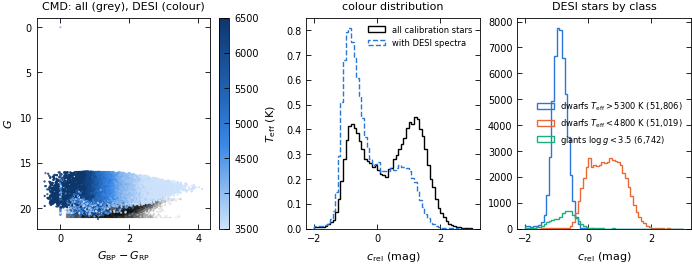

In [5]:
teff, logg, feh = S['teff'][st], S['logg'][st], S['feh'][st]
# one row per star: Gaia G and BP-RP (the colour of the CMD), c_rel of its first epoch (x axis of the DCR diagram)
G, bprp, crel = S['G'][st], S['bp_rp'][st], S['c_rel'][st]
Ga, bprpa, crela = A['G'][sa], A['bp_rp'][sa], A['c_rel'][sa]
dwarf_hot = (logg > 3.8) & (teff > 5300)
dwarf_cool = (logg > 3.8) & (teff < 4800)
giant = logg < 3.5
fig, ax = plt.subplots(1, 3, figsize=(ps.PAGE, 2.7), constrained_layout=True)
ax[0].hexbin(bprpa, Ga, gridsize=70, extent=(0.2, 3.5, 15.5, 21), bins='log', cmap=ps.DENSITY, mincnt=1)
sc = ax[0].scatter(bprp, G, c=teff, s=0.3, cmap=ps.SEQUENTIAL, vmin=3500, vmax=6500, rasterized=True)
ax[0].invert_yaxis(); ax[0].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); ax[0].set_ylabel('$G$')
ax[0].set_title('CMD: all (grey), DESI (colour)')
fig.colorbar(sc, ax=ax[0], label=r'$T_{\rm eff}$ (K)')
bins = np.linspace(-2, 3, 61)
ax[1].hist(crela, bins=bins, density=True, histtype='step', color='k', label='all calibration stars')
ax[1].hist(crel, bins=bins, density=True, histtype='step', color=ps.SERIES[0], ls='--', label='with DESI spectra')
ax[1].set_xlabel(r'$c_{\rm rel}$ (mag)'); ax[1].set_title('colour distribution'); ax[1].legend(fontsize=6)
for k, (s, lab) in enumerate([(dwarf_hot, r'dwarfs $T_{\rm eff}>5300$ K'), (dwarf_cool, r'dwarfs $T_{\rm eff}<4800$ K'),
                              (giant, r'giants $\log g<3.5$')]):
    ax[2].hist(crel[s], bins=bins, histtype='step', color=ps.SERIES[k], label=f'{lab} ({s.sum():,})')
ax[2].set_xlabel(r'$c_{\rm rel}$ (mag)'); ax[2].set_title('DESI stars by class'); ax[2].legend(fontsize=6)
plt.savefig(OUT + 'dcr_spectra_cmd.pdf')
print('fraction of DESI stars: hot dwarfs %.2f, cool dwarfs %.2f, giants %.2f' % (dwarf_hot.mean(), dwarf_cool.mean(), giant.mean()))

## B. Does colour pin down the SED? T_eff and [Fe/H] at fixed colour

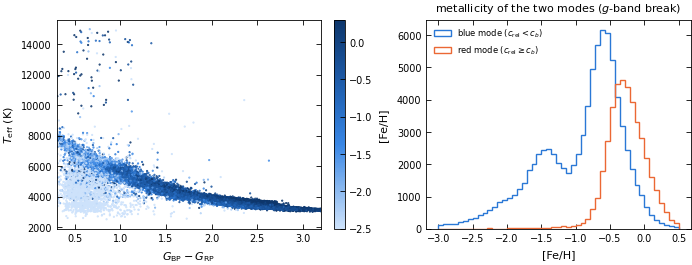

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(ps.PAGE, 2.7), constrained_layout=True)
sc = ax[0].scatter(bprp, teff, c=feh, s=0.3, cmap=ps.SEQUENTIAL, vmin=-2.5, vmax=0.3, rasterized=True)
ax[0].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); ax[0].set_ylabel(r'$T_{\rm eff}$ (K)'); ax[0].set_xlim(0.3, 3.2)
fig.colorbar(sc, ax=ax[0], label='[Fe/H]')
ax[1].hist(feh[crel < 0.05], bins=np.linspace(-3, 0.5, 50), histtype='step', color=ps.SERIES[0], label=r'blue mode ($c_{\rm rel}<c_b$)')
ax[1].hist(feh[crel >= 0.05], bins=np.linspace(-3, 0.5, 50), histtype='step', color=ps.SERIES[1], label=r'red mode ($c_{\rm rel}\geq c_b$)')
ax[1].set_xlabel('[Fe/H]'); ax[1].legend(fontsize=6); ax[1].set_title('metallicity of the two modes ($g$-band break)')
plt.savefig(OUT + 'dcr_spectra_teff_feh.pdf')

## C. DCR at fixed colour by metallicity and surface gravity

Offset along the parallactic direction per unit tan z, in c_rel bins, before the correction (the DCR diagram) and after
the two-line correction (what is left). If the SED at fixed colour mattered, metal-poor stars (and giants) would sit
off the metal-rich dwarfs.

after DCR, weighted mean residual offset / tan z (mas) per group, tan z 0.3-1.3:
  g  [Fe/H] > -0.5                 +0.52 +- 0.04   (410,952 epochs)
  g  -1.2 < [Fe/H] < -0.5          +2.25 +- 0.04   (337,330 epochs)
  g  [Fe/H] < -1.2                 -0.77 +- 0.06   (218,635 epochs)
  g  giants ($\log g<3.5$)         +1.86 +- 0.11   (55,069 epochs)
  r  [Fe/H] > -0.5                 +1.18 +- 0.03   (393,705 epochs)
  r  -1.2 < [Fe/H] < -0.5          +1.70 +- 0.03   (310,925 epochs)
  r  [Fe/H] < -1.2                 +1.86 +- 0.04   (200,206 epochs)
  r  giants ($\log g<3.5$)         +2.25 +- 0.08   (49,770 epochs)
  i  [Fe/H] > -0.5                 +1.44 +- 0.03   (346,047 epochs)
  i  -1.2 < [Fe/H] < -0.5          +1.86 +- 0.03   (275,092 epochs)
  i  [Fe/H] < -1.2                 +2.19 +- 0.04   (176,438 epochs)
  i  giants ($\log g<3.5$)         +2.72 +- 0.08   (41,889 epochs)
  z  [Fe/H] > -0.5                 +1.89 +- 0.03   (401,350 epochs)
  z  -1.2 < [Fe/H] < -0.5          +2.

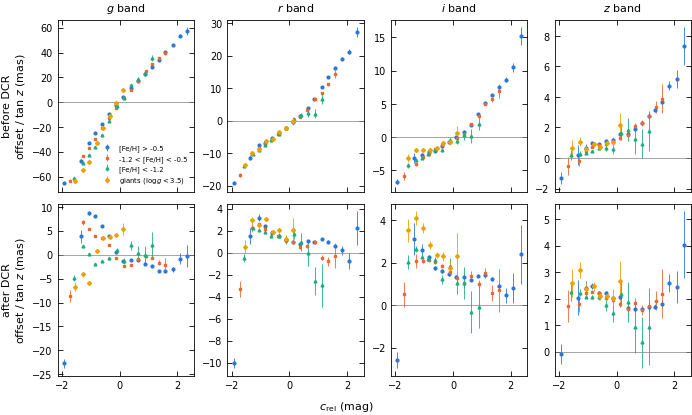

In [7]:
C_EDGES = np.linspace(-1.5, 2.5, 17)
T_EDGES = np.array([0.3, 1.3])
groups = [('[Fe/H] > -0.5', lambda: S['feh'] > -0.5), ('-1.2 < [Fe/H] < -0.5', lambda: (S['feh'] > -1.2) & (S['feh'] <= -0.5)),
          ('[Fe/H] < -1.2', lambda: S['feh'] <= -1.2), (r'giants ($\log g<3.5$)', lambda: S['logg'] < 3.5)]
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 4.2), sharex=True, constrained_layout=True)
summary = {}
for row, stage in enumerate(['raw', 'dcr']):
    for ax, band in zip(axes[row], 'griz'):
        for k, (lab, f) in enumerate(groups):
            q = m & f() & (S['band'] == band) & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3)
            cells = dcr_fit.binned_2d(S['c_rel'][q], S['tanz'][q], S[f'par_{stage}'][q], C_EDGES, T_EDGES, min_count=100)
            if not len(cells):
                continue
            ax.errorbar(cells[0] + 0.02 * k, cells[2] / cells[1], cells[3] / cells[1], fmt=ps.MARKERS[k], ms=2, lw=0.6,
                        color=ps.SERIES[k], label=lab)
            if stage == 'dcr':
                w = 1 / (cells[3] / cells[1])**2
                mu = np.sum(w * cells[2] / cells[1]) / w.sum()
                summary[(band, lab)] = (mu, 1 / np.sqrt(w.sum()), int(q.sum()))
        ax.axhline(0, color='0.5', lw=0.5)
        if row == 0:
            ax.set_title(f'${band}$ band')
    axes[row, 0].set_ylabel(('before DCR' if stage == 'raw' else 'after DCR') + '\noffset / tan $z$ (mas)')
axes[0, 0].legend(fontsize=5)
fig.supxlabel(r'$c_{\rm rel}$ (mag)', fontsize=8)
plt.savefig(OUT + 'dcr_spectra_by_feh.pdf')
print('after DCR, weighted mean residual offset / tan z (mas) per group, tan z 0.3-1.3:')
for (band, lab), (mu, e, n) in summary.items():
    print(f'  {band}  {lab:28s} {mu:+6.2f} +- {e:.2f}   ({n:,} epochs)')

In [8]:
# the alpha-enhancement question (James): at fixed colour and [Fe/H] < -0.8, high vs low [alpha/Fe], g band, after DCR
for band in 'gr':
    for lab, s in [('[a/Fe] > 0.25', S['alphafe'] > 0.25), ('[a/Fe] < 0.15', S['alphafe'] < 0.15)]:
        q = m & s & (S['band'] == band) & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3) & (S['logg'] > 3.8)
        cells = dcr_fit.binned_2d(S['c_rel'][q], S['tanz'][q], S['par_dcr'][q], C_EDGES, T_EDGES, min_count=100)
        if len(cells):
            w = (cells[1] / cells[3])**2
            print(f'{band} {lab}: residual offset / tan z {np.sum(w * cells[2] / cells[1]) / w.sum():+.2f} +- {1/np.sqrt(w.sum()):.2f} mas ({q.sum():,} epochs)')

g [a/Fe] > 0.25: residual offset / tan z +0.91 +- 0.04 mas (454,985 epochs)
g [a/Fe] < 0.15: residual offset / tan z -0.23 +- 0.05 mas (220,684 epochs)
r [a/Fe] > 0.25: residual offset / tan z +1.59 +- 0.03 mas (417,521 epochs)


r [a/Fe] < 0.15: residual offset / tan z +1.27 +- 0.04 mas (215,754 epochs)
